# Yi-Ning Li
# DSCI 552
# HW 3 (scroll down for HW 4)

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import warnings
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### a) Download data

In [2]:
dataPath='../data/AReM'
activities=['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

### b) Training and test data

In [3]:
trainFiles=[]
testFiles=[]

for activity in activities:
    folderPath=os.path.join(dataPath, activity)
    files=[f for f in os.listdir(folderPath) if f.endswith('.csv')]

    for fileName in files:
        datasetNum=int(fileName.replace('dataset', '').replace('.csv', ''))

        if activity in ['bending1', 'bending2']: 
            if datasetNum in [1, 2]:
                testFiles.append((activity, fileName))
            else: 
                trainFiles.append((activity, fileName))
        else: 
            if datasetNum in [1, 2, 3]:
                testFiles.append((activity, fileName))
            else: 
                trainFiles.append((activity, fileName))

print('Training instances:', len(trainFiles))
print('Testing instances:', len(testFiles))

Training instances: 69
Testing instances: 19


### c) Feature extraction

#### i. Time-domain features

Common time-domain features: minimum, maximum, mean, median, standard deviation, variance, range, first quartile, third quartile, interquartile range, skewness, kurtosis

#### ii. Extraction: minimum, maximum, mean, median, standard deviation, Q1, Q3

In [4]:
def extractFeatures(filePath):
    if 'bending2' in filePath and 'dataset4.csv' in filePath:
        data=pd.read_csv(filePath, skiprows=5, header=None, sep=r'\s+')
    elif 'cycling' in filePath and ('dataset14.csv' in filePath or 'dataset9.csv' in filePath):
        data=pd.read_csv(filePath, skiprows=5, header=None, usecols=range(7))
    else:
        data=pd.read_csv(filePath, skiprows=5, header=None)
        
    data.columns=[
        'time',
        'avg_rss12',
        'var_rss12',
        'avg_rss13',
        'var_rss13',
        'avg_rss23',
        'var_rss23'
    ]
    
    features=[]
    
    for column in data.columns[1:]:
        series=data[column]
        features.extend([
            series.min(),
            series.max(),
            series.mean(),
            series.median(),
            series.std(),
            series.quantile(0.25),
            series.quantile(0.75)
        ])
        
    return features

In [5]:
featureNames=[]
for i in range(1, 7):
    featureNames.extend([
        f'min{i}',
        f'max{i}',
        f'mean{i}',
        f'median{i}',
        f'std{i}',
        f'firstQuart{i}',
        f'thirdQuart{i}',
    ])

In [6]:
allFeatures=[]
instanceNames=[]

for activity in activities:
    folderPath=os.path.join(dataPath, activity)
    files=[f for f in os.listdir(folderPath) if f.endswith('.csv')]

    for fileName in files:
        filePath=os.path.join(folderPath, fileName)

        print(activity, fileName)
        
        features=extractFeatures(filePath)

        allFeatures.append(features)
        instanceNames.append(activity + ' ' + fileName)

bending1 dataset1.csv
bending1 dataset2.csv
bending1 dataset3.csv
bending1 dataset4.csv
bending1 dataset5.csv
bending1 dataset6.csv
bending1 dataset7.csv
bending2 dataset1.csv
bending2 dataset2.csv
bending2 dataset3.csv
bending2 dataset4.csv
bending2 dataset5.csv
bending2 dataset6.csv
cycling dataset1.csv
cycling dataset10.csv
cycling dataset11.csv
cycling dataset12.csv
cycling dataset13.csv
cycling dataset14.csv
cycling dataset15.csv
cycling dataset2.csv
cycling dataset3.csv
cycling dataset4.csv
cycling dataset5.csv
cycling dataset6.csv
cycling dataset7.csv
cycling dataset8.csv
cycling dataset9.csv
lying dataset1.csv
lying dataset10.csv
lying dataset11.csv
lying dataset12.csv
lying dataset13.csv
lying dataset14.csv
lying dataset15.csv
lying dataset2.csv
lying dataset3.csv
lying dataset4.csv
lying dataset5.csv
lying dataset6.csv
lying dataset7.csv
lying dataset8.csv
lying dataset9.csv
sitting dataset1.csv
sitting dataset10.csv
sitting dataset11.csv
sitting dataset12.csv
sitting dataset

In [7]:
featureData=pd.DataFrame(allFeatures, columns=featureNames)
featureData.insert(0, 'Instance', instanceNames)

The shape and first five rows of the feature dataset are shown to verify its dimensions and structure.

In [8]:
print(featureData.shape)
featureData.head()

(88, 43)


,Instance,min1,max1,mean1,median1,std1,firstQuart1,thirdQuart1,min2,max2,...,std5,firstQuart5,thirdQuart5,min6,max6,mean6,median6,std6,firstQuart6,thirdQuart6
0,bending1 dataset1.csv,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1 dataset2.csv,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1 dataset3.csv,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1 dataset4.csv,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1 dataset5.csv,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


#### iii. Standard deviation of each extracted feature and 90% bootstrap CI

In [9]:
np.random.seed(42)

bootstrapResults=[]

for feature in featureNames:
    values=featureData[feature].values

    stdEstimate=np.std(values, ddof=1)

    bootstrapStds=[]

    for i in range(1000):
        bootstrapSample=np.random.choice(values, size=len(values), replace=True)
        bootstrapStds.append(np.std(bootstrapSample, ddof=1))
    
    lowerBound=np.percentile(bootstrapStds, 5)
    upperBound=np.percentile(bootstrapStds, 95)

    bootstrapResults.append([
        feature, 
        stdEstimate,
        lowerBound,
        upperBound
    ])

bootstrapData=pd.DataFrame(
    bootstrapResults,
    columns=[
        'Feature',
        'Standard Deviation',
        '90% CI Lower',
        '90% CI Upper'
    ]
)

bootstrapData

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.569975,8.241109,10.782064
1,max1,4.394362,3.309103,5.313409
2,mean1,5.335718,4.716600,5.873198
3,median1,5.440054,4.777178,5.999269
4,std1,1.772153,1.570897,1.953811
5,firstQuart1,6.153590,5.619249,6.678478
6,thirdQuart1,5.138925,4.373560,5.875915
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.600773,5.394303
9,mean2,1.574164,1.399285,1.713035


#### iv. Selected features

To select the three most important time-domain features, choose features that represent central tendency, position/extremeness, and variability. 

For central tendency, choose between mean and median. 
For position/extremeness, choose between min, max, Q1, and Q3. 
For variability, choose standard deviation. 

Within the above selections, compare how well each feature separates the different activity classes. Use separation score based on range of activity means relative to overall standard deviation. Features with higher separation scores are considered more important since it indicates the feature differs more across activity classes relative to its overall variability. For example, if mean has a higher separation score than median, then mean is selected for central tendency. 

In [10]:
separationScores={}
featureData['Activity']=featureData['Instance'].str.split(' ').str[0]

for feature in featureNames:
    activityMeans=featureData.groupby('Activity')[feature].mean()
    meanRange=activityMeans.max()-activityMeans.min()
    overallStd=featureData[feature].std()

    if overallStd==0:
        separationScores[feature]=0
    else:
        separationScores[feature]=meanRange/overallStd

featureTypes=[
    'min',
    'max',
    'mean',
    'median',
    'std',
    'firstQuart',
    'thirdQuart'
]

averageScores={}

for featureType in featureTypes:
    matchingFeatures=[
        feature for feature in featureNames
        if feature.startswith(featureType)
    ]

    scores=[
        separationScores[feature]
        for feature in matchingFeatures
    ]

    averageScores[featureType]=np.mean(scores)

averageScores=pd.Series(averageScores).sort_values(ascending=False)

averageScores

firstQuart    2.800087
median        2.773027
mean          2.761256
thirdQuart    2.718936
max           2.401130
std           2.199325
min           1.327539
dtype: float64

Central tendency: Median has a higher separation score than mean --> choose median
Position/extremeness: Q1 has the highest separation score --> choose Q1
Variability: Choose standard deviation

Therefore, using the statistical meaning of the features and quantitative comparison via separation scores, the three most important time-domain features are 
1. median for central tendency
2. Q1 for position/extremeness
3. standard deviation for variability. 

## 2. ISLR 3.7.4

 I collect a set of data (n = 100 observations) containing a single
predictor and a quantitative response. I then fit a linear regression
model to the data, as well as a separate cubic regression, i.e. Y =
β0 + β1X + β2X^2 + β3X^3 + ϵ.

(a) Suppose that the true relationship between X and Y is linear,
i.e. Y = β0 + β1X + ϵ. Consider the training residual sum of
squares (RSS) for the linear regression, and also the training
RSS for the cubic regression. Would we expect one to be lower
than the other, would we expect them to be the same, or is there
not enough information to tell? Justify your answer.

(b) Answer (a) using test rather than training RSS.

(c) Suppose that the true relationship between X and Y is not linear,
but we don’t know how far it is from linear. Consider the training
RSS for the linear regression, and also the training RSS for the
cubic regression. Would we expect one to be lower than the
other, would we expect them to be the same, or is there not
enough information to tell? Justify your answer.

(d) Answer (c) using test rather than training RSS.

a) The cubic regression is expected to have a training RSS lower than or equal to the linear training RSS. The cubic model has more flexibility and can always fit the training data at least as well as the linear model. It contains the linear model itself when β2 and β3 are both 0. 

b) The linear regression is expected to have a lower test RSS. Since the true relationship is linear, the X^2 and X^3 terms in the cubic model are not necessary. Thus, they may fit noise in the training data, increasing variance and potentially hurting generalization. 

c) The cubic regression is expected to have a training RSS less than or equal to the linear regression because the cubic model is more flexible and inherently contains the linear model, thus being able to fit the data at least as well as the linear model. 

d) There is not enough information to tell if the linear regression or cubic regression will have a lower test RSS; the extent of nonlinearity in the data would need to be known. If the true relationship is well approximated by a cubic function, then cubic regression is expected to have a lower test RSS. However, if the true relationship is only slightly nonlinear, then the cubic model may overfit and the linear model may have the lower test RSS. 

# HW 4 begins here

## 1. Same as HW 3, see above

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### a. Binary Classification Using Logistic Regression

#### i. Scatter plots

In [11]:
trainFeatures=[]
trainLabels=[]

for activity, fileName in trainFiles:
    filePath=os.path.join(dataPath, activity, fileName)
    features=extractFeatures(filePath)
    trainFeatures.append(features)
    if activity in ['bending1', 'bending2']:
        trainLabels.append('Bending')
    else:
        trainLabels.append('Other')

    trainFeatureData=pd.DataFrame(trainFeatures, columns=featureNames)
    trainFeatureData['Class']=trainLabels
    trainFeatureData.head()

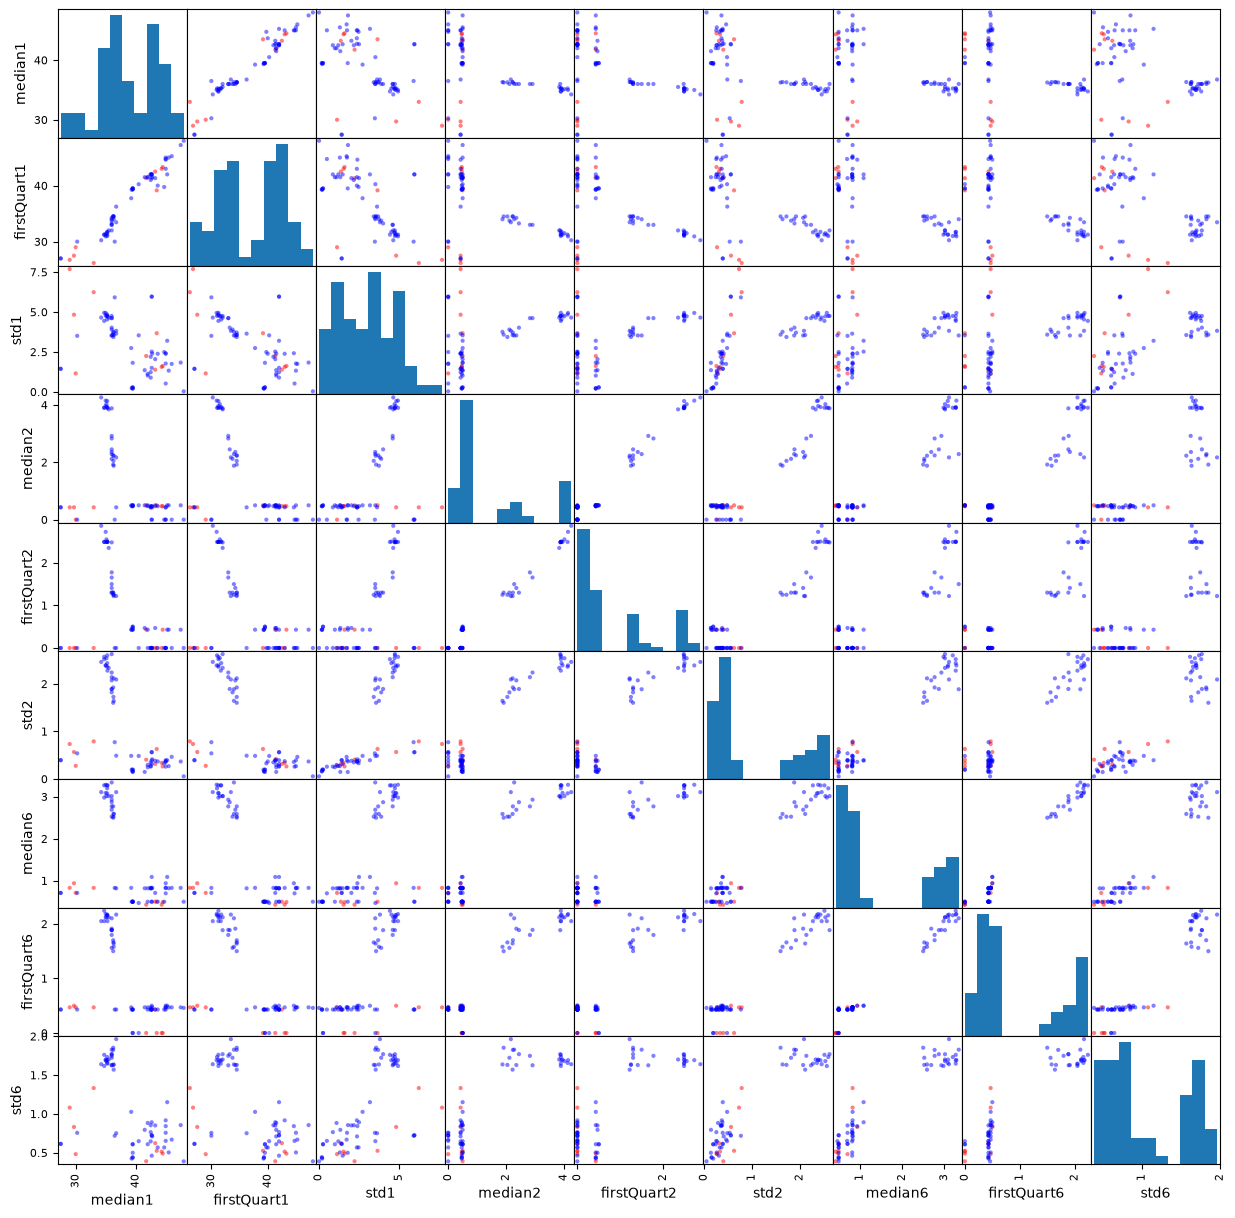

In [12]:
selectedFeatures=[
    'median1', 'firstQuart1', 'std1',
    'median2', 'firstQuart2', 'std2',
    'median6', 'firstQuart6', 'std6'
]

colors=trainFeatureData['Class'].map({
    'Bending': 'red',
    'Other': 'blue'
})

scatterMatrix=scatter_matrix(
    trainFeatureData[selectedFeatures],
    figsize=(15, 15),
    c=colors,
    diagonal='hist'
)

The scatter plot matrix shows that the bending class is rather distinguishable from the other activities using the selected time-domain features from time series 1, 2, and 6. The bending observations in red are concentrated in a smaller region of the feature space, while the other activities in blue are more widely distributed. There is some overlap so the classes are not perfectly separated, but the selected features appear useful for binary classification. 

#### ii. Split

In [13]:
def extractSplitFeatures(filePath, numSplits=2):
    data = pd.read_csv(
        filePath,
        skiprows=4,
        usecols=range(1, 7),
        engine='python'
    )

    splitIndices = np.array_split(np.arange(len(data)), numSplits)
    features = []

    for indices in splitIndices:
        splitData = data.iloc[indices]
        for column in splitData.columns:
            values = splitData[column].values
            features.extend([
                np.median(values),
                np.percentile(values, 25),
                np.std(values, ddof=1)
            ])

    return features

In [14]:
trainSplitFeatures = []
trainSplitLabels = []

for activity, fileName in trainFiles:
    filePath = os.path.join(dataPath, activity, fileName)

    features = extractSplitFeatures(filePath, numSplits=2)
    trainSplitFeatures.append(features)

    if activity in ['bending1', 'bending2']:
        trainSplitLabels.append('Bending')
    else:
        trainSplitLabels.append('Other')

splitFeatureNames = []

for splitNum in range(1, 3):
    for timeSeriesNum in range(1, 7):
        splitFeatureNames.extend([
            f'median{timeSeriesNum}Split{splitNum}',
            f'firstQuart{timeSeriesNum}Split{splitNum}',
            f'std{timeSeriesNum}Split{splitNum}'
        ])

trainSplitFeatureData = pd.DataFrame(
    trainSplitFeatures,
    columns=splitFeatureNames
)

trainSplitFeatureData['Class'] = trainSplitLabels

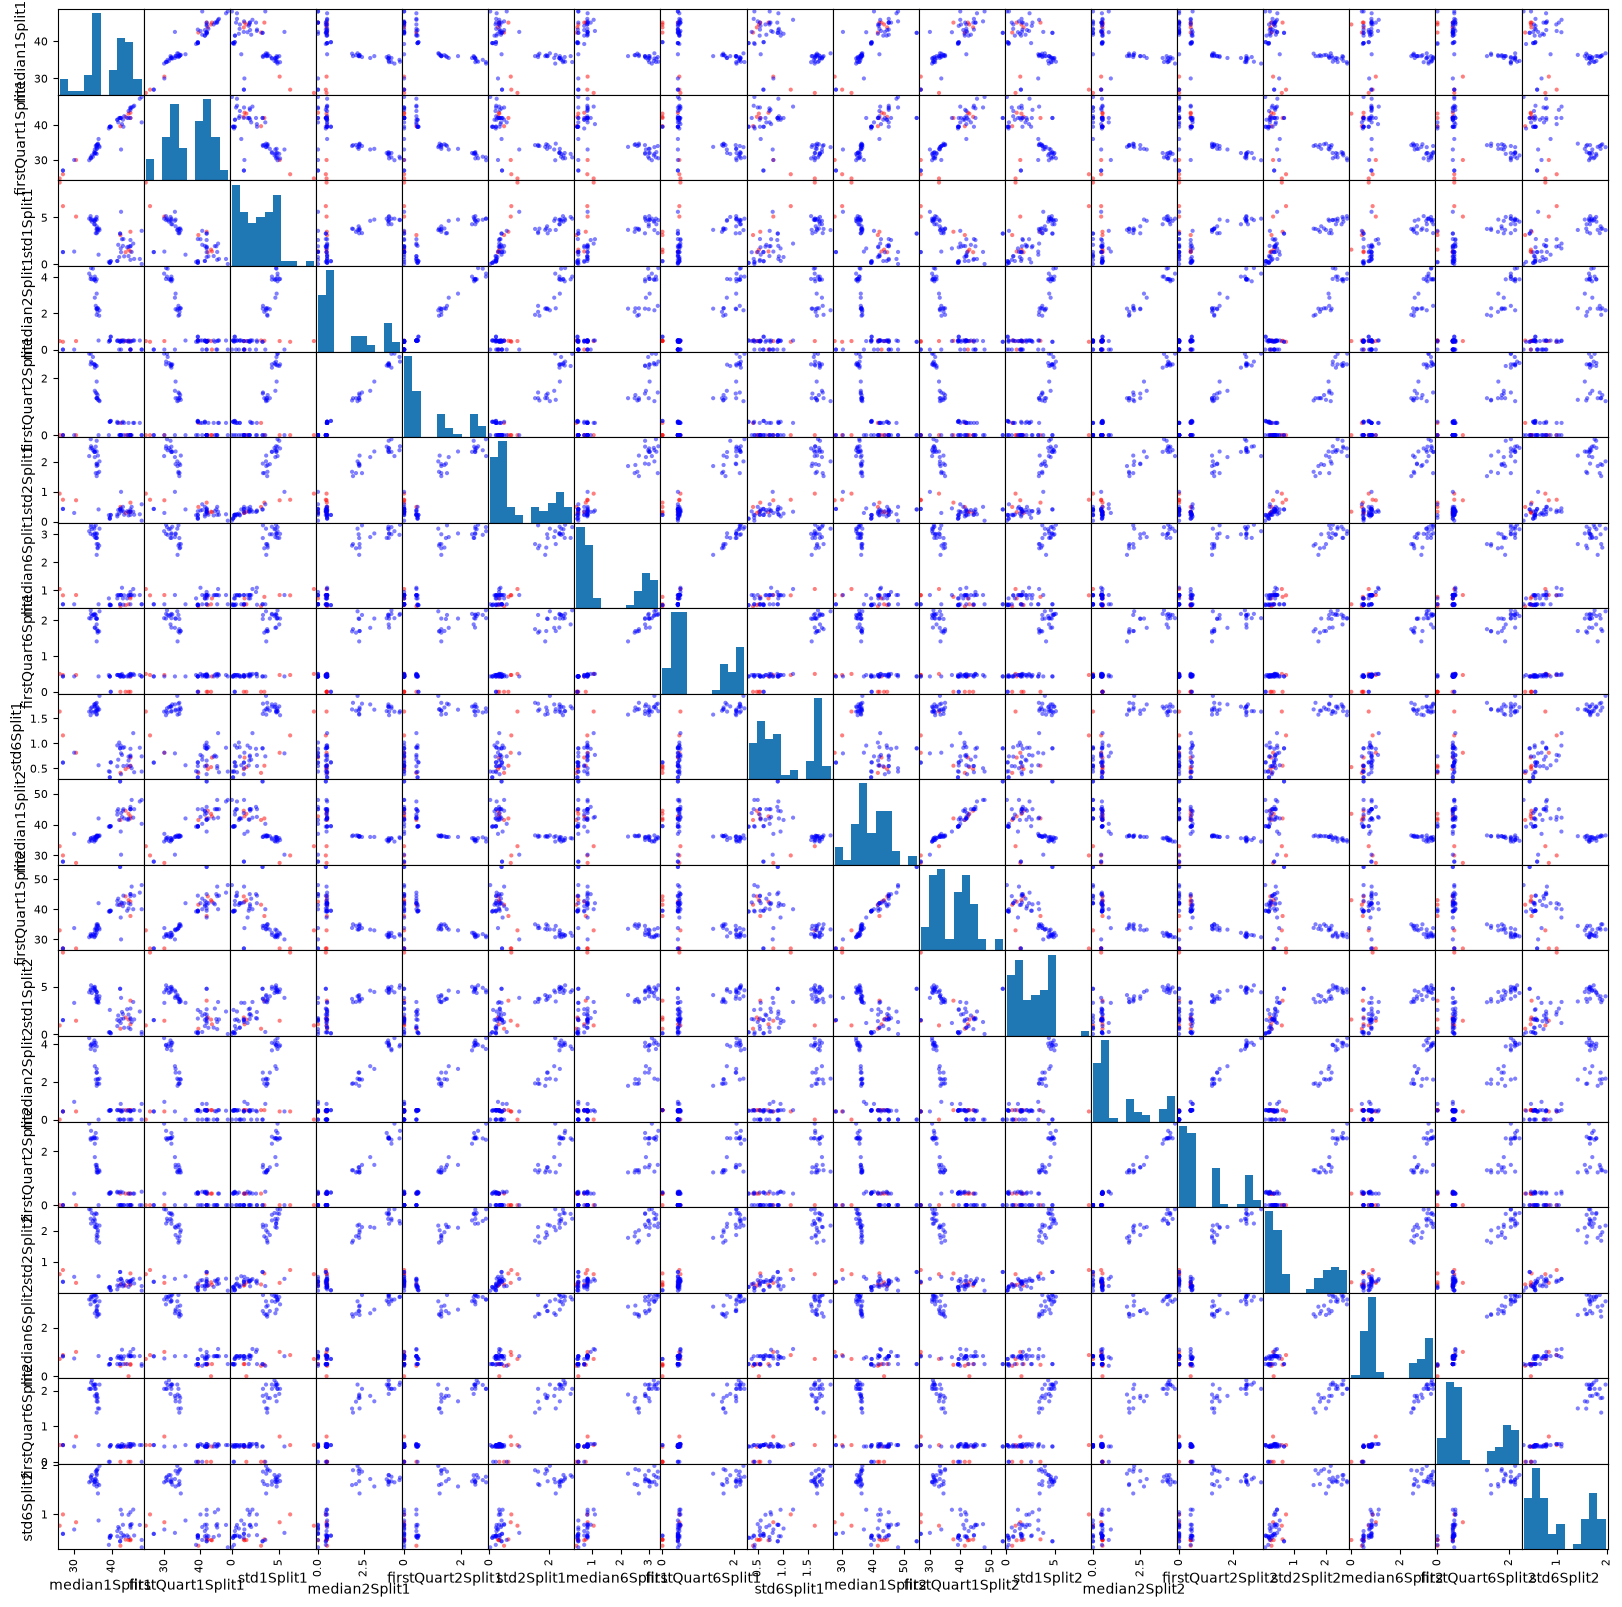

In [15]:
selectedSplitFeatures = [
    'median1Split1', 'firstQuart1Split1', 'std1Split1',
    'median2Split1', 'firstQuart2Split1', 'std2Split1',
    'median6Split1', 'firstQuart6Split1', 'std6Split1',
    'median1Split2', 'firstQuart1Split2', 'std1Split2',
    'median2Split2', 'firstQuart2Split2', 'std2Split2',
    'median6Split2', 'firstQuart6Split2', 'std6Split2'
]

plotData = trainSplitFeatureData[
    selectedSplitFeatures + ['Class']
].dropna().reset_index(drop=True)

colors = plotData['Class'].map({
    'Bending': 'red',
    'Other': 'blue'
}).to_numpy()

scatterMatrix = scatter_matrix(
    plotData[selectedSplitFeatures],
    figsize=(20, 20),
    c=colors,
    diagonal='hist'
)

plt.show()

After splitting each time series into two approximately equal parts, the scatter plots show patterns similar to those in 2ai. The bending observations are still concentrated in smaller regions of the feature space, while the other activities are more dispersed. Although splitting the time series provides additional features and slightly more detailed information, there is no considerable improvement in the visual separation between the bending and non-bending classes. 

#### iii. 

In [16]:
def extractAllSplitFeatures(filePath, numSplits):
    data=pd.read_csv(
        filePath,
        skiprows=4,
        usecols=range(1, 7),
        engine='python'
    )

    splitIndices=np.array_split(np.arange(len(data)), numSplits)
    features=[]
    for indices in splitIndices:
        splitData=data.iloc[indices]
        for column in splitData.columns:
            values=splitData[column].values

            features.extend([
                np.min(values),
                np.max(values),
                np.mean(values),
                np.median(values),
                np.std(values, ddof=1),
                np.percentile(values, 25),
                np.percentile(values, 75)
            ])

    return features

In [17]:
warnings.filterwarnings('ignore')

bestScore = -1
bestL = None
bestP = None
cvResults = []
stratifiedCV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for l in range(1, 21):
    print('Testing l =', l)
    xData = []
    yData = []

    for activity, fileName in trainFiles:
        filePath = os.path.join(dataPath, activity, fileName)
        features = extractAllSplitFeatures(
            filePath,
            numSplits=l
        )

        xData.append(features)
        if activity in ['bending1', 'bending2']:
            yData.append(1)
        else:
            yData.append(0)

    xData = np.array(xData)
    yData = np.array(yData)

    for p in range(1, 10):
        rfe = RFE(
            estimator=LogisticRegression(
                penalty=None,
                max_iter=300
            ),
            n_features_to_select=p,
            step=0.25
        )

        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('rfe', rfe),
            ('logistic', LogisticRegression(
                penalty=None,
                max_iter=300
            ))
        ])

        scores = cross_val_score(
            pipeline,
            xData,
            yData,
            cv=stratifiedCV,
            scoring='accuracy'
        )

        meanScore = scores.mean()
        cvResults.append([
            l,
            p,
            meanScore
        ])

        print(
            '   p =', p,
            'accuracy =', round(meanScore, 4)
        )

        if meanScore > bestScore:
            bestScore = meanScore
            bestL = l
            bestP = p

Testing l = 1
   p = 1 accuracy = 0.8846
   p = 2 accuracy = 0.8846
   p = 3 accuracy = 0.9132
   p = 4 accuracy = 0.9132
   p = 5 accuracy = 0.9132
   p = 6 accuracy = 0.8989
   p = 7 accuracy = 0.8978
   p = 8 accuracy = 0.8989
   p = 9 accuracy = 0.8989
Testing l = 2
   p = 1 accuracy = 0.8846
   p = 2 accuracy = 0.8846
   p = 3 accuracy = 0.8846
   p = 4 accuracy = 0.8703
   p = 5 accuracy = 0.8703
   p = 6 accuracy = 0.8264
   p = 7 accuracy = 0.8396
   p = 8 accuracy = 0.8692
   p = 9 accuracy = 0.8549
Testing l = 3
   p = 1 accuracy = 0.9571
   p = 2 accuracy = 0.9571
   p = 3 accuracy = 0.9429
   p = 4 accuracy = 0.9429
   p = 5 accuracy = 0.9429
   p = 6 accuracy = 0.9132
   p = 7 accuracy = 0.8418
   p = 8 accuracy = 0.8703
   p = 9 accuracy = 0.8703
Testing l = 4
   p = 1 accuracy = 0.8703
   p = 2 accuracy = 0.9132
   p = 3 accuracy = 0.9418
   p = 4 accuracy = 0.8857
   p = 5 accuracy = 0.8857
   p = 6 accuracy = 0.856
   p = 7 accuracy = 0.8846
   p = 8 accuracy = 0.8703


In [18]:
print('Best l:', bestL)
print('Best p:', bestP)
print('Best CV Accuracy:', bestScore)

Best l: 3
Best p: 1
Best CV Accuracy: 0.9571428571428571


A coarse search over $p=\{5,10,20\}$ indicated that smaller values of $p$ performed best. A finer search over $p=1,\ldots,9$ was then performed. The best pair found was $l=3$ and $p=1$, with a 5-fold cross-validation accuracy of approximately 0.9571.

The correct way to perform cross-validation is to carry out feature selection separately within each training fold. This prevents information from the validation fold from influencing which features are selected. The wrong way is to apply RFE to the entire training dataset first and then perform cross-validation. This would cause data leakage and produce an overly optimistic estimate of model performance. Stratified 5-fold cross-validation was used because the bending class is less frequent than the other class. 

In [19]:
bestL = 3
bestP = 1

xData = []
yData = []

for activity, fileName in trainFiles:
    filePath = os.path.join(dataPath, activity, fileName)
    features = extractAllSplitFeatures(
        filePath,
        numSplits=bestL
    )

    xData.append(features)
    if activity in ['bending1', 'bending2']:
        yData.append(1)
    else:
        yData.append(0)

xData = np.array(xData)
yData = np.array(yData)

In [20]:
featureNames = []
statNames = [
    'min',
    'max',
    'mean',
    'median',
    'std',
    'firstQuart',
    'thirdQuart'
]

for splitNum in range(1, bestL + 1):
    for timeSeriesNum in range(1, 7):
        for statName in statNames:
            featureNames.append(
                f'{statName}{timeSeriesNum}Split{splitNum}'
            )

imputer=SimpleImputer(strategy='median')
xDataImputed=imputer.fit_transform(xData)

logisticModel=LogisticRegression(penalty=None, max_iter=1000)
rfe=RFE(estimator=logisticModel, n_features_to_select=bestP, step=0.25)
rfe.fit(xDataImputed, yData)

selectedFeatureNames=np.array(featureNames)[rfe.support_]

print('Selected feature: ')
print(selectedFeatureNames)

Selected feature: 
['max5Split1']


In [21]:
selectedX = xDataImputed[:, rfe.support_]
selectedX = sm.add_constant(selectedX)
logitModel = sm.Logit(yData, selectedX)
logitResult = logitModel.fit()

print(logitResult.summary())

Optimization terminated successfully.
         Current function value: 0.099523
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       67
Method:                           MLE   Df Model:                            1
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.7430
Time:                        20:29:18   Log-Likelihood:                -6.8671
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 2.960e-10
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -20.0685      6.394     -3.139      0.002     -32.601      -7.536
x1             0.6983      0.

In [22]:
print('Intercept:', logitResult.params[0])
print('Beta for', selectedFeatureNames[0], ':', logitResult.params[1])
print('Intercept p-value:', logitResult.pvalues[0])
print(
    selectedFeatureNames[0],
    'p-value:',
    logitResult.pvalues[1]
)

Intercept: -20.068483039370584
Beta for max5Split1 : 0.698337328997053
Intercept p-value: 0.0016975596354911163
max5Split1 p-value: 0.0034988860378913746


Using 5-fold stratified cross-validation with RFE, the best pair was l=3 and p=1 with a cross-validation accuracy of about 0.9571. The selected feature was max5Split1. The fitted logistic regression coefficient for this feature was 0.6983 with a p-value of 0.00350, indicating that it is statistically significant. 

#### iv. confusion matrix and ROC/AUC

Confusion matrix: 
[[60  0]
 [ 1  8]]
Training AUC:  0.9518518518518517


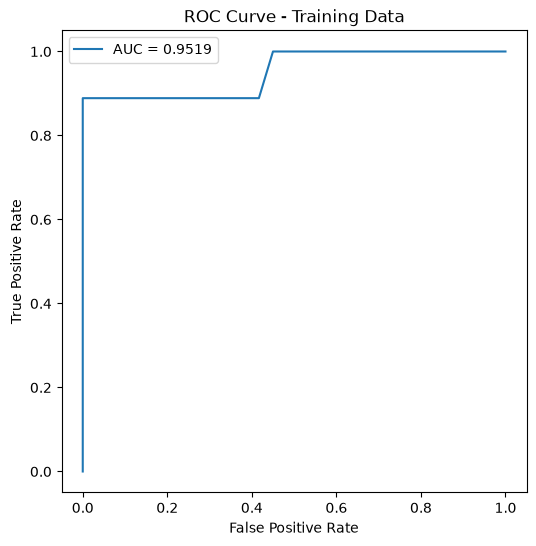

In [23]:
trainProbabilities=logitResult.predict(selectedX)
trainPredictions=(trainProbabilities>=0.5).astype(int)
confusionMatrix=confusion_matrix(yData, trainPredictions)

print('Confusion matrix: ')
print(confusionMatrix)

trainAUC=roc_auc_score(yData, trainProbabilities)
falsePositiveRate, truePositiveRate, thresholds=roc_curve(yData, trainProbabilities)

print('Training AUC: ', trainAUC)

plt.figure(figsize=(6, 6))
plt.plot(falsePositiveRate, truePositiveRate, label=f'AUC = {trainAUC:.4f}')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Training Data')
plt.legend()
plt.show()

In [24]:
trainAcc=(confusionMatrix[0, 0]+confusionMatrix[1, 1])/69*100
print('Training Accuracy: ', trainAcc)

Training Accuracy:  98.55072463768117


The training confusion matrix was:

|                  | Predicted Other | Predicted Bending |
|------------------|----------------:|------------------:|
| Actual Other     | 60              | 0                 |
| Actual Bending   | 1               | 8                 |

The classifier correctly classified 68 of 69 training instances, giving a training accuracy of 98.55%. The training AUC was 0.9519, indicating strong discrimination between bending and non-bending activities.
$$
\log\left(\frac{p}{1-p}\right)
=
-20.0685 + 0.6983(\mathrm{max5Split1})
$$

The p-value for max5Split1 was 0.00350, and the p-value for the intercept was 0.00170.

#### v. Test set

In [25]:
testX = []
testY = []

for activity, fileName in testFiles:
    filePath = os.path.join(dataPath, activity, fileName)
    features = extractAllSplitFeatures(
        filePath,
        numSplits=bestL
    )

    testX.append(features)
    if activity in ['bending1', 'bending2']:
        testY.append(1)
    else:
        testY.append(0)

testXImputed = imputer.transform(testX)
selectedTestX = testXImputed[:, rfe.support_]
selectedTestX = sm.add_constant(selectedTestX)
testProbabilities = logitResult.predict(selectedTestX)
testPredictions = (testProbabilities >= 0.5).astype(int)
testAccuracy = (testPredictions == testY).mean()

print('Test Accuracy:', testAccuracy)
print('Cross-Validation Accuracy:', bestScore)

testConfusionMatrix = confusion_matrix(
    testY,
    testPredictions
)

print('Test Confusion Matrix:')
print(testConfusionMatrix)

Test Accuracy: 0.8947368421052632
Cross-Validation Accuracy: 0.9571428571428571
Test Confusion Matrix:
[[15  0]
 [ 2  2]]


The test confusion matrix was:

|                  | Predicted Other | Predicted Bending |
|------------------|----------------:|------------------:|
| Actual Other     | 15              | 0                 |
| Actual Bending   | 2               | 2                 |

The test accuracy was 89.47%, while the 5-fold cross-validation accuracy was 95.71%. The test accuracy was therefore 6.24 percentage points lower than the cross-validation accuracy.
The classifier correctly classified all 15 non-bending test instances, but only 2 of the 4 bending test instances. This indicates that the model generalized reasonably well overall, but its performance on the bending class was weaker on the test set.

#### vi. 

The classes do not appear to be perfectly separated. Although the classifier performs well on the training set, one bending instance was still misclassified. In addition, the logistic regression converged and produced finite coefficient estimates and p-values. Therefore, there is no strong evidence of complete or quasi-complete separation causing instability in the logistic regression parameters.

#### vii. 

In [26]:
caseIndices = np.where(yData == 1)[0]
controlIndices = np.where(yData == 0)[0]

np.random.seed(42)

sampledControlIndices = np.random.choice(
    controlIndices,
    size=len(caseIndices),
    replace=False
)

caseControlIndices = np.concatenate([
    caseIndices,
    sampledControlIndices
])

caseControlX = xDataImputed[
    caseControlIndices
][:, rfe.support_]

caseControlY = yData[caseControlIndices]

In [27]:
caseControlXConst = sm.add_constant(caseControlX)

caseControlModel = sm.Logit(
    caseControlY,
    caseControlXConst
)

caseControlResult = caseControlModel.fit()

print(caseControlResult.params)

Optimization terminated successfully.
         Current function value: 0.204037
         Iterations 9
[-15.70007499   0.60567523]


In [28]:
populationProb = yData.mean()
sampleProb = caseControlY.mean()

interceptAdjustment = np.log(
    populationProb / (1 - populationProb)
) - np.log(
    sampleProb / (1 - sampleProb)
)

adjustedParams = caseControlResult.params.copy()

adjustedParams[0] = (
    adjustedParams[0]
    + interceptAdjustment
)

print('Adjusted Intercept:', adjustedParams[0])
print('Beta:', adjustedParams[1])

Adjusted Intercept: -17.597194977135718
Beta: 0.6056752275222526


In [29]:
fullSelectedX = xDataImputed[:, rfe.support_]

adjustedLogOdds = (
    adjustedParams[0]
    + adjustedParams[1] * fullSelectedX[:, 0]
)

adjustedProbabilities = 1 / (
    1 + np.exp(-adjustedLogOdds)
)

adjustedPredictions = (
    adjustedProbabilities >= 0.5
).astype(int)

In [30]:
caseControlConfusionMatrix = confusion_matrix(
    yData,
    adjustedPredictions
)

caseControlAUC = roc_auc_score(
    yData,
    adjustedProbabilities
)

print('Confusion Matrix:')
print(caseControlConfusionMatrix)

print('AUC:', caseControlAUC)

Confusion Matrix:
[[60  0]
 [ 1  8]]
AUC: 0.9518518518518517


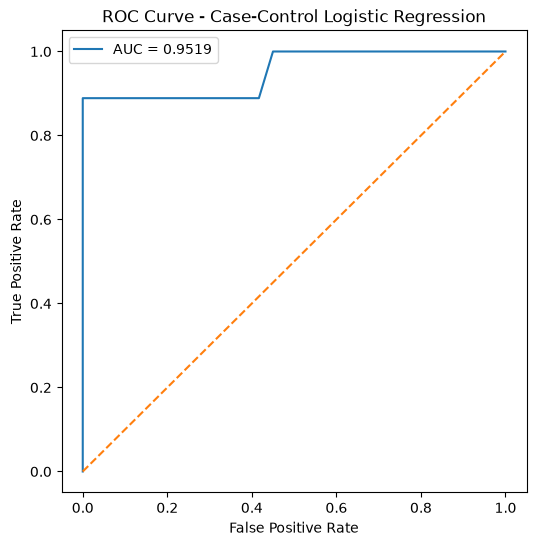

In [31]:
falsePositiveRate, truePositiveRate, thresholds = roc_curve(
    yData,
    adjustedProbabilities
)

plt.figure(figsize=(6, 6))

plt.plot(
    falsePositiveRate,
    truePositiveRate,
    label=f'AUC = {caseControlAUC:.4f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Case-Control Logistic Regression')
plt.legend()

plt.show()

The training data are imbalanced, with 60 non-bending instances and 9 bending instances. Therefore, a case-control logistic regression model was constructed by using all bending instances and randomly sampling an equal number of non-bending instances.

After fitting the model on the balanced case-control sample, the intercept was adjusted to account for the original class proportions in the full training data.

The adjusted case-control model produced the following confusion matrix:

|                  | Predicted Other | Predicted Bending |
|------------------|----------------:|------------------:|
| Actual Other     | 60              | 0                 |
| Actual Bending   | 1               | 8                 |

The AUC was 0.9519. The adjusted case-control model produced the same classification performance as the original logistic regression model on the training data.

### b. Binary Classification Using L1-penalized logistic regression

#### i. 

In [32]:
bestL1Score = -1
bestL1L = None
bestL1C = None
l1Results = []
cValues = [0.01, 0.1, 1, 10, 100]
stratifiedCV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for l in range(1, 21):
    print('Testing l =', l)
    xData = []
    yData = []

    for activity, fileName in trainFiles:
        filePath = os.path.join(dataPath, activity, fileName)
        features = extractAllSplitFeatures(
            filePath,
            numSplits=l
        )

        xData.append(features)
        if activity in ['bending1', 'bending2']:
            yData.append(1)
        else:
            yData.append(0)

    xData = np.array(xData)
    yData = np.array(yData)

    for c in cValues:
        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('logistic', LogisticRegression(
                penalty='l1',
                C=c,
                solver='liblinear',
                max_iter=1000
            ))
        ])

        scores = cross_val_score(
            pipeline,
            xData,
            yData,
            cv=stratifiedCV,
            scoring='accuracy'
        )

        meanScore = scores.mean()
        l1Results.append([
            l,
            c,
            meanScore
        ])

        print(
            '   C =', c,
            'accuracy =', round(meanScore, 4)
        )

        if meanScore > bestL1Score:
            bestL1Score = meanScore
            bestL1L = l
            bestL1C = c

Testing l = 1
   C = 0.01 accuracy = 0.8703
   C = 0.1 accuracy = 0.8989
   C = 1 accuracy = 0.9714
   C = 10 accuracy = 0.9275
   C = 100 accuracy = 0.9275
Testing l = 2
   C = 0.01 accuracy = 0.8703
   C = 0.1 accuracy = 0.8846
   C = 1 accuracy = 0.9571
   C = 10 accuracy = 0.9132
   C = 100 accuracy = 0.9121
Testing l = 3
   C = 0.01 accuracy = 0.8703
   C = 0.1 accuracy = 0.8703
   C = 1 accuracy = 0.9571
   C = 10 accuracy = 0.9275
   C = 100 accuracy = 0.9275
Testing l = 4
   C = 0.01 accuracy = 0.8703
   C = 0.1 accuracy = 0.8703
   C = 1 accuracy = 0.9275
   C = 10 accuracy = 0.9275
   C = 100 accuracy = 0.9132
Testing l = 5
   C = 0.01 accuracy = 0.8703
   C = 0.1 accuracy = 0.8703
   C = 1 accuracy = 0.9275
   C = 10 accuracy = 0.9132
   C = 100 accuracy = 0.9132
Testing l = 6
   C = 0.01 accuracy = 0.8703
   C = 0.1 accuracy = 0.8989
   C = 1 accuracy = 0.9571
   C = 10 accuracy = 0.9275
   C = 100 accuracy = 0.8835
Testing l = 7
   C = 0.01 accuracy = 0.8703
   C = 0.1 acc

In [33]:
print('Best l:', bestL1L)
print('Best C:', bestL1C)
print('Best CV Accuracy:', bestL1Score)

Best l: 1
Best C: 1
Best CV Accuracy: 0.9714285714285715


Using L1-penalized logistic regression with 5-fold stratified cross-validation, the best model was obtained with \(l=1\) and \(C=1\). The corresponding cross-validation accuracy was 97.14%.

Because L1 regularization shrinks some coefficients to zero, it performs feature selection automatically while fitting the logistic regression model.

#### ii. 

The L1-penalized logistic regression achieved a higher cross-validation accuracy (97.14%) than the logistic regression model using RFE/p-value-based feature selection (95.71%). Therefore, the L1-penalized model performed slightly better.

L1 regularization was also easier to implement because feature selection occurs automatically through coefficient shrinkage, whereas the RFE/p-value approach required a separate feature-selection procedure and additional model fitting.

### c. Multi-class Classification (The Realistic Case)

#### i. 

In [34]:
bestMultiScore = -1
bestMultiL = None
bestMultiC = None
multiResults = []
cValues = [0.01, 0.1, 1, 10, 100]

for l in range(1, 21):
    print('Testing l =', l)
    xData = []
    yData = []

    for activity, fileName in trainFiles:
        filePath = os.path.join(dataPath, activity, fileName)
        features = extractAllSplitFeatures(
            filePath,
            numSplits=l
        )

        xData.append(features)
        yData.append(activity)
    xData = np.array(xData)
    yData = np.array(yData)

    for c in cValues:
        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('logistic', LogisticRegression(
                penalty='l1',
                C=c,
                solver='saga',
                max_iter=3000
            ))
        ])

        scores = cross_val_score(
            pipeline,
            xData,
            yData,
            cv=stratifiedCV,
            scoring='accuracy'
        )

        meanScore = scores.mean()
        multiResults.append([
            l,
            c,
            meanScore
        ])

        print(
            '   C =', c,
            'accuracy =', round(meanScore, 4)
        )

        if meanScore > bestMultiScore:
            bestMultiScore = meanScore
            bestMultiL = l
            bestMultiC = c

Testing l = 1
   C = 0.01 accuracy = 0.1451
   C = 0.1 accuracy = 0.6374
   C = 1 accuracy = 0.9143
   C = 10 accuracy = 0.856
   C = 100 accuracy = 0.856
Testing l = 2
   C = 0.01 accuracy = 0.1593
   C = 0.1 accuracy = 0.6802
   C = 1 accuracy = 0.8714
   C = 10 accuracy = 0.8857
   C = 100 accuracy = 0.9
Testing l = 3
   C = 0.01 accuracy = 0.1736
   C = 0.1 accuracy = 0.5945
   C = 1 accuracy = 0.8132
   C = 10 accuracy = 0.8132
   C = 100 accuracy = 0.856
Testing l = 4
   C = 0.01 accuracy = 0.1593
   C = 0.1 accuracy = 0.6374
   C = 1 accuracy = 0.7846
   C = 10 accuracy = 0.856
   C = 100 accuracy = 0.8275
Testing l = 5
   C = 0.01 accuracy = 0.1736
   C = 0.1 accuracy = 0.5659
   C = 1 accuracy = 0.8264
   C = 10 accuracy = 0.8418
   C = 100 accuracy = 0.8846
Testing l = 6
   C = 0.01 accuracy = 0.1593
   C = 0.1 accuracy = 0.5945
   C = 1 accuracy = 0.7989
   C = 10 accuracy = 0.7978
   C = 100 accuracy = 0.8275
Testing l = 7
   C = 0.01 accuracy = 0.1593
   C = 0.1 accuracy =

In [35]:
print('Best l:', bestMultiL)
print('Best C:', bestMultiC)
print('Best CV Accuracy:', bestMultiScore)

Best l: 1
Best C: 1
Best CV Accuracy: 0.9142857142857143


The best l and best C were found to be both 1, with the highest CV accuracy of 0.9143. Executing the previous code is slow, so the findings are reported here. 

In [36]:
bestMultiL = 1
bestMultiC = 1
trainMultiX = []
trainMultiY = []

for activity, fileName in trainFiles:
    filePath = os.path.join(dataPath, activity, fileName)
    features = extractAllSplitFeatures(
        filePath,
        numSplits=bestMultiL
    )

    trainMultiX.append(features)
    trainMultiY.append(activity)
trainMultiX = np.array(trainMultiX)
trainMultiY = np.array(trainMultiY)

In [37]:
multiPipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        penalty='l1',
        C=bestMultiC,
        solver='saga',
        max_iter=3000
    ))
])

multiPipeline.fit(
    trainMultiX,
    trainMultiY
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U8](7,)","['bending1','bending2','cycling',...,'sitting','standing','walking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imput

In [38]:
testMultiX = []
testMultiY = []

for activity, fileName in testFiles:
    filePath = os.path.join(dataPath, activity, fileName)
    features = extractAllSplitFeatures(
        filePath,
        numSplits=bestMultiL
    )
    testMultiX.append(features)
    testMultiY.append(activity)
testMultiX = np.array(testMultiX)
testMultiY = np.array(testMultiY)

In [39]:
testMultiPredictions = multiPipeline.predict(
    testMultiX
)

testMultiAccuracy = (
    testMultiPredictions == testMultiY
).mean()

testMultiError = 1 - testMultiAccuracy

print('Test Accuracy:', testMultiAccuracy)
print('Test Error:', testMultiError)

multiConfusionMatrix = confusion_matrix(
    testMultiY,
    testMultiPredictions,
    labels=multiPipeline.classes_
)

multiConfusionMatrixData = pd.DataFrame(
    multiConfusionMatrix,
    index=multiPipeline.classes_,
    columns=multiPipeline.classes_
)

display(multiConfusionMatrixData)

Test Accuracy: 0.8947368421052632
Test Error: 0.10526315789473684


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,1,0,2,0
walking,0,0,0,0,0,0,3


Using the best L1-penalized multinomial logistic regression model with \(l=1\) and \(C=1\), the test accuracy was 89.47%, corresponding to a test error of 10.53%.

The confusion matrix showed that most activities were classified correctly. The model misclassified one 'sitting' instance as 'standing' and one 'standing' instance as 'lying.' All other test instances were classified correctly.

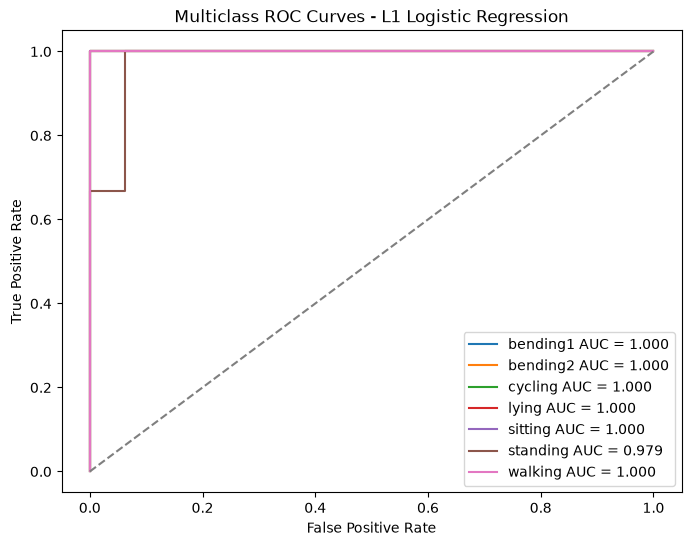

In [40]:
testMultiProbabilities = multiPipeline.predict_proba(testMultiX)
classes = multiPipeline.classes_
testMultiYBinary = label_binarize(
    testMultiY,
    classes=classes
)

plt.figure(figsize=(8, 6))

for i, className in enumerate(classes):
    falsePositiveRate, truePositiveRate, thresholds = roc_curve(
        testMultiYBinary[:, i],
        testMultiProbabilities[:, i]
    )

    classAUC = auc(
        falsePositiveRate,
        truePositiveRate
    )

    plt.plot(
        falsePositiveRate,
        truePositiveRate,
        label=f'{className} AUC = {classAUC:.3f}'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves - L1 Logistic Regression')
plt.legend()
plt.show()

The one-vs-rest ROC curves show a strong class discrimination. The AUC was 1.000 for bending1, bending2, cycling, lying, sitting, and walking, while the AUC for standing was 0.979. Overall, the multiclass L1-penalized logistic regression model showed excellent discrimination among the activity classes.

#### ii. 

In [41]:
gaussianModel = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('gaussianNB', GaussianNB())
])

gaussianModel.fit(trainMultiX, trainMultiY)
gaussianPredictions = gaussianModel.predict(testMultiX)
gaussianAccuracy = accuracy_score(
    testMultiY,
    gaussianPredictions
)
gaussianError = 1 - gaussianAccuracy

print('Gaussian NB Accuracy:', gaussianAccuracy)
print('Gaussian NB Error:', gaussianError)

multinomialModel = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('multinomialNB', MultinomialNB())
])

multinomialModel.fit(trainMultiX, trainMultiY)
multinomialPredictions = multinomialModel.predict(testMultiX)
multinomialAccuracy = accuracy_score(
    testMultiY,
    multinomialPredictions
)

multinomialError = 1 - multinomialAccuracy

print('Multinomial NB Accuracy:', multinomialAccuracy)
print('Multinomial NB Error:', multinomialError)

Gaussian NB Accuracy: 0.7894736842105263
Gaussian NB Error: 0.21052631578947367
Multinomial NB Accuracy: 0.7894736842105263
Multinomial NB Error: 0.21052631578947367


In [42]:
gaussianConfusionMatrix = confusion_matrix(
    testMultiY,
    gaussianPredictions,
    labels=gaussianModel.classes_
)

gaussianConfusionMatrixData = pd.DataFrame(
    gaussianConfusionMatrix,
    index=gaussianModel.classes_,
    columns=gaussianModel.classes_
)

print('Gaussian Naive Bayes confusion matrix: ')
display(gaussianConfusionMatrixData)

multinomialConfusionMatrix = confusion_matrix(
    testMultiY,
    multinomialPredictions,
    labels=multinomialModel.classes_
)

multinomialConfusionMatrixData = pd.DataFrame(
    multinomialConfusionMatrix,
    index=multinomialModel.classes_,
    columns=multinomialModel.classes_
)

print('\nMultinomial Naive Bayes confusion matrix: ')
display(multinomialConfusionMatrixData)

Gaussian Naive Bayes confusion matrix: 


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,0,0,0,2,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3



Multinomial Naive Bayes confusion matrix: 


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,1,2,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Both Gaussian Naive Bayes and Multinomial Naive Bayes achieved a test accuracy of 78.95%, corresponding to a test error of 21.05%.

Although their overall accuracies were identical, the two classifiers produced different misclassification patterns. Gaussian Naive Bayes tended to misclassify several activities as 'sitting', while Multinomial Naive Bayes distributed its errors across multiple classes.

#### iii. 

The L1-penalized multinomial logistic regression performed better than both Naive Bayes classifiers. Its test accuracy was 89.47%, compared with 78.95% for both Gaussian Naive Bayes and Multinomial Naive Bayes. Therefore, the L1-penalized multinomial logistic regression was the best multiclass classification method for this dataset.

## 3. ISLR 4.8.3

For class $k$,
$$
X \sim N(\mu_k,\sigma_k^2)
$$
and the class-conditional density is
$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\,\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$
The Bayes classifier chooses the class that maximizes $\pi_k f_k(x)$. Taking logs and dropping constants common to all classes gives
$$
\delta_k(x)
=
\log \pi_k
-
\log \sigma_k
-
\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$
Expanding the squared term,
$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-
\log\sigma_k
+
\log\pi_k.
$$

Because $\sigma_k^2$ is class-specific, the coefficient of $x^2$ differs between classes. Therefore, the decision boundary obtained by setting $\delta_k(x)=\delta_j(x)$ contains a quadratic term in $x$. Hence, the Bayes classifier is not linear, it is quadratic.

## 4. ISLR 4.8.7

Using Bayes' theorem,
$$
P(\mathrm{Yes}\mid X=4)
=
\frac{
P(X=4\mid \mathrm{Yes})P(\mathrm{Yes})
}{
P(X=4\mid \mathrm{Yes})P(\mathrm{Yes})
+
P(X=4\mid \mathrm{No})P(\mathrm{No})
}.
$$
The given values are
$$
\mu_{\mathrm{Yes}}=10,\qquad
\mu_{\mathrm{No}}=0,\qquad
\sigma^2=36,
$$
so
$$
\sigma=6.
$$
Also,
$$
P(\mathrm{Yes})=0.8,
\qquad
P(\mathrm{No})=0.2.
$$
For $X=4$,
$$
f_{\mathrm{Yes}}(4)
=
\frac{1}{\sqrt{2\pi}\cdot 6}
\exp\left(
-\frac{(4-10)^2}{2(36)}
\right),
$$
and
$$
f_{\mathrm{No}}(4)
=
\frac{1}{\sqrt{2\pi}\cdot6}
\exp\left(
-\frac{(4-0)^2}{2(36)}
\right).
$$
Since the common factor cancels,
$$
P(\mathrm{Yes}\mid X=4)
=
\frac{
0.8e^{-36/72}
}{
0.8e^{-36/72}
+
0.2e^{-16/72}
}
\approx 0.752.
$$

Therefore, the probability that the company will issue a dividend is approximately 75.2%.